# Copula-based pairs trading on gold and silver: dependence analysis and backtest results

Adapts the copula pairs-trading framework of Krauss & Stübinger (2015) to GLD/SLV, with three
robustness pairs. All results are read from `data/pairs.sqlite`, produced by
`python -m scripts.run_experiments`. Figures are saved to `reports/figures/`.

**Research use only, not investment advice.** Backtests on historical data do not predict future returns.

| | Source |
|---|---|
| t-copula, conditional-probability signals (α = 5%), quantile TP/SL exit, 50 bps cost | Paper (cited) |
| GLD/SLV + 3 pairs, free data 2006–2025, monthly walk-forward refit, z-score baseline | This project |
| Gaussian vs t out-of-sample comparison, tail calibration, cost sensitivity | This project (extension) |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cpt import analysis, copula, plots
from cpt.backtest import copula_frame
from cpt.config import db_path, load_config
from cpt.db import connect, load_adj_close

cfg = load_config()
s = {**cfg["strategy"], "paper_quantile": cfg["paper_quantile"]}
conn = connect(db_path(cfg))
plots.set_style()
pd.set_option("display.float_format", "{:.4f}".format)

PAIRS = [cfg["pairs"]["main"], *cfg["pairs"]["robustness"]]
PAIR_NAMES = [f"{a}-{b}" for a, b in PAIRS]
MAIN = PAIR_NAMES[0]
SPEC_NAMES = {
    "copula|t|probability": "Copula t (main)",
    "copula|gaussian|probability": "Copula Gaussian",
    "copula|t|paper_quantile": "Copula t, paper exit",
    "zscore|None|None": "z-score baseline",
}

## 1. Data

Adjusted closes from yfinance, inner-joined on common trading days. The first 12 months of each
pair are used only for estimation, so trading starts 2007-06 (GDX-GDXJ: 2010-12).

In [2]:
prices = {name: load_adj_close(conn, list(p)) for name, p in zip(PAIR_NAMES, PAIRS)}
pd.DataFrame({n: {"start": p.index.min().date(), "end": p.index.max().date(), "days": len(p)}
              for n, p in prices.items()}).T

,start,end,days
GLD-SLV,2006-05-01,2025-12-31,4950
GDX-GDXJ,2009-11-11,2025-12-31,4059
XOM-CVX,2006-05-01,2025-12-31,4950
KO-PEP,2006-05-01,2025-12-31,4950


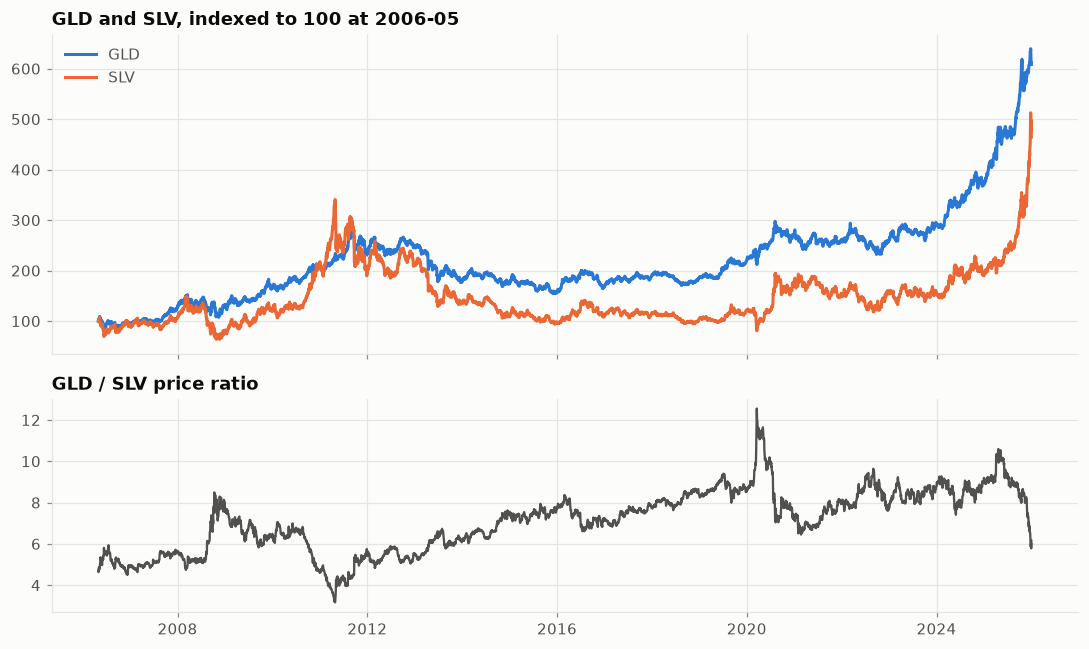

In [3]:
fig = plots.prices_and_ratio(prices[MAIN])
plots.save(fig, "01_prices_and_ratio");

## 2. RQ1: Is there dependence that Pearson correlation misses?

Full-sample daily log returns. `pearson_implied_by_kendall` = sin(πτ/2) is the linear correlation an
elliptical copula would imply from Kendall's τ; a gap to Pearson points to nonlinearity or outliers.
Joint-tail columns: share of days on which both legs are below (above) their own 5% (95%) quantile;
under independence this would be 0.25%.

In [4]:
dep = pd.DataFrame({n: analysis.dependence_summary(np.log(p).diff()) for n, p in prices.items()}).T
dep

,n,pearson,spearman,kendall,pearson_implied_by_kendall,joint_lower_tail,joint_upper_tail,independence_tail
GLD-SLV,4949.0000,0.7925,0.7910,0.6059,0.8144,0.0275,0.0232,0.0025
GDX-GDXJ,4058.0000,0.9504,0.9496,0.8132,0.9573,0.0360,0.0377,0.0025
XOM-CVX,4949.0000,0.8562,0.8267,0.6496,0.8523,0.0313,0.0309,0.0025
KO-PEP,4949.0000,0.6961,0.6586,0.4869,0.6924,0.0240,0.0218,0.0025


## 3. RQ2: Does the t-copula fit better than the Gaussian copula?

Each month both copulas are fit on the previous 12 months and evaluated on the next month
(out-of-sample log-likelihood, using the training ECDF for the new month's returns).

In [5]:
frames, fits = {}, {}
for name in PAIR_NAMES:
    frames[name], fits[name] = copula_frame(prices[name], s, "t", "probability")
pd.DataFrame({n: analysis.fit_comparison(f) for n, f in fits.items()}).T

,months,t_better_aic_share,t_better_oos_share,oos_loglik_diff_total,median_nu,median_tail_dep
GLD-SLV,223.0000,0.5919,0.5650,88.7516,9.7750,0.3175
GDX-GDXJ,181.0000,0.6243,0.5746,52.3953,8.6315,0.6366
XOM-CVX,223.0000,0.9821,0.6906,247.0695,4.1300,0.5339
KO-PEP,223.0000,0.8161,0.6861,139.4631,5.2773,0.3380


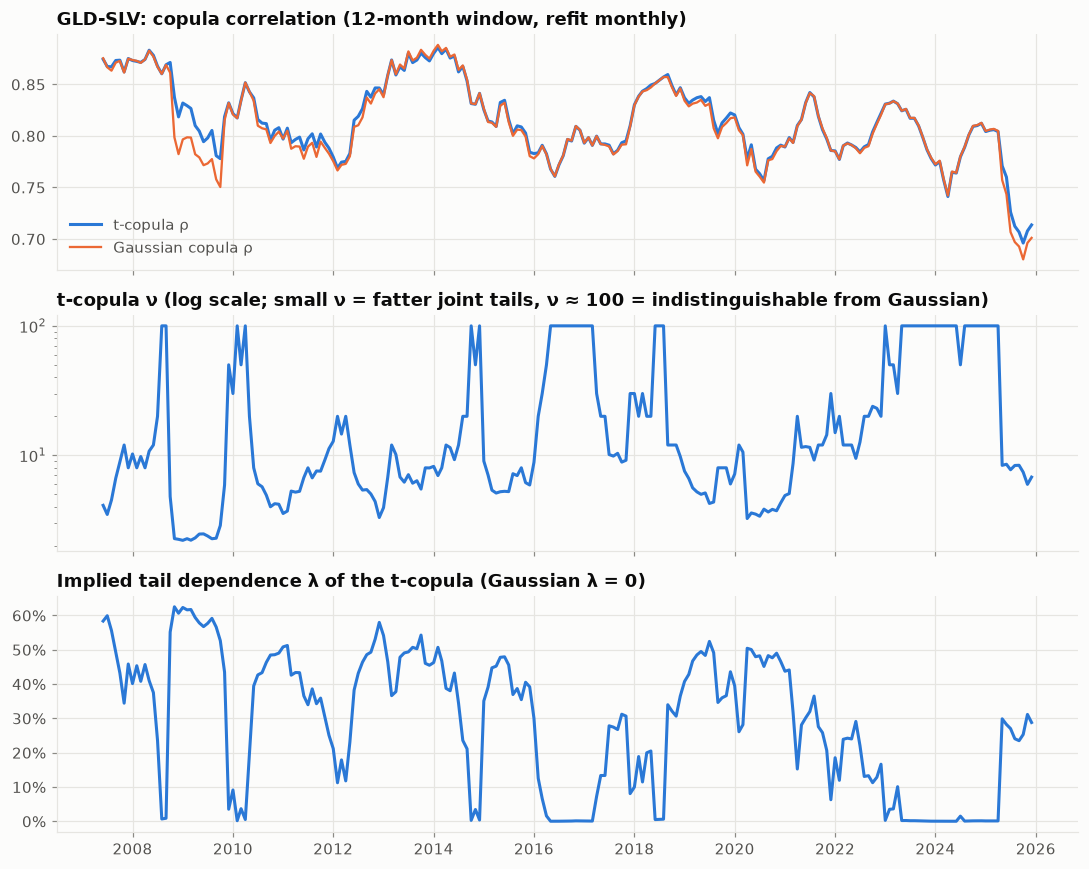

In [6]:
fig = plots.rolling_parameters(fits[MAIN], MAIN)
plots.save(fig, "03_rolling_copula_parameters");

**Out-of-sample tail calibration.** For each month the fitted copulas predict how many days both legs
fall beyond their 5% tails, C(q, q) × days. Summed over all months and compared with what happened.
Both copulas are symmetric, so they predict the same count for the lower and upper tails.

In [7]:
Q = 0.05
calib = pd.DataFrame({n: analysis.oos_tail_calibration(fits[n], frames[n], Q).drop(columns="month").sum()
                      for n in PAIR_NAMES}).T
calib_share = calib.drop(columns="days").div(calib["days"], axis=0)
calib_share

,observed_lower,observed_upper,pred_gaussian,pred_t
GLD-SLV,0.0297,0.0239,0.0256,0.0275
GDX-GDXJ,0.0424,0.0398,0.0380,0.0389
XOM-CVX,0.0325,0.0297,0.0267,0.0305
KO-PEP,0.0289,0.0216,0.0196,0.0232


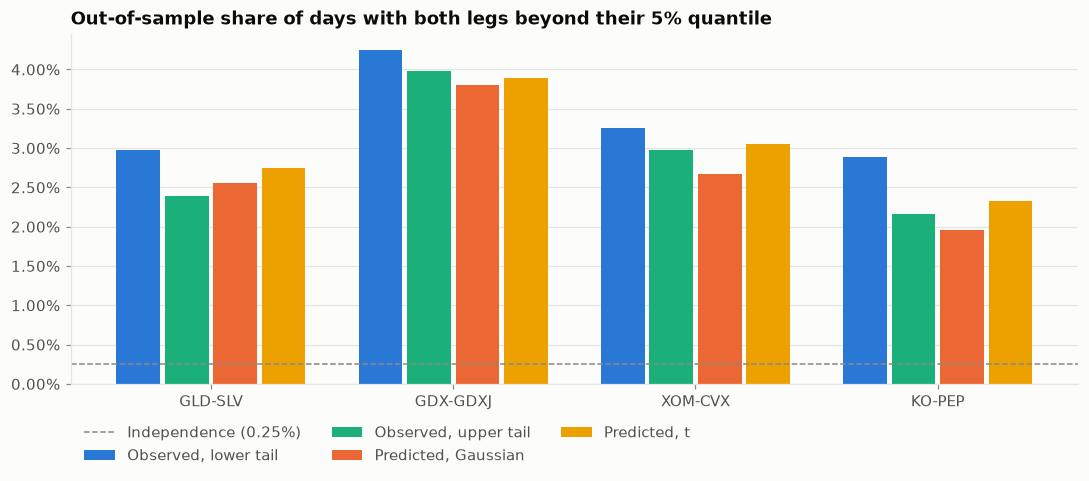

In [8]:
fig = plots.tail_calibration(calib, Q)
plots.save(fig, "04_tail_calibration");

**Signal regions for one window.** Latest month in the sample: grey points are the 12-month estimation
window, black points the out-of-sample month. Shaded areas are regions A and B where trades open.

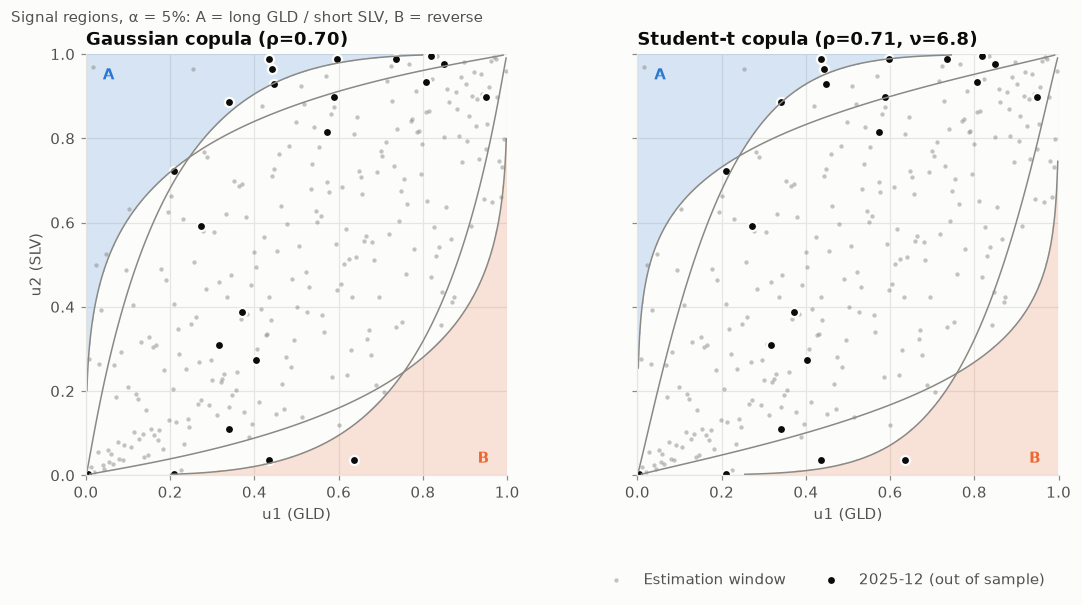

In [9]:
r = np.log(prices[MAIN]).diff().dropna()
month = r.index.to_period("M")
last = month.max()
first = int(np.argmax(month == last))
train, test = r.iloc[first - s["estimation_window_days"]:first], r[month == last]
tr = [train.iloc[:, i].to_numpy() for i in range(2)]
train_u = tuple(copula.pseudo_observations(x) for x in tr)
test_u = tuple(copula.ecdf_transform(tr[i], test.iloc[:, i].to_numpy()) for i in range(2))
fig = plots.copula_bands(train_u, test_u, copula.fit_gaussian(*train_u), copula.fit_t(*train_u),
                         s["alpha"], tuple(cfg["pairs"]["main"]), str(last))
plots.save(fig, "02_copula_signal_regions");

## 4. RQ3–RQ5: Strategy results

Main specification: t-copula, probability exit, one-day execution lag, 50 bps round-trip cost per pair
trade. Other specifications were registered in `config.yaml` before their results were seen.
`breakeven_bps` is the average gross return per trade, i.e. the round-trip cost at which the average
trade nets zero.

In [10]:
runs = pd.read_sql("SELECT * FROM experiment_runs", conn)
metrics = pd.read_sql("SELECT * FROM run_metrics", conn).pivot(index="run_id", columns="metric", values="value")
runs = runs.join(metrics, on="run_id")
runs["spec"] = (runs["model"] + "|" + runs["family"].fillna("None") + "|" + runs["exit_rule"].fillna("None")).map(SPEC_NAMES)
runs.loc[runs["model"] == "buy_hold", "spec"] = runs["family"]

cols = ["ann_return", "ann_vol", "sharpe", "sortino", "max_drawdown", "var_95", "cvar_95",
        "n_trades", "avg_holding_days", "win_rate", "breakeven_bps"]
main_table = runs[(runs["pair"] == MAIN) & runs["cost_bps"].isin([0, 50])]
main_table.set_index(["spec", "cost_bps"])[cols].sort_index()

ann_return  ann_vol  sharpe  sortino  \
spec                 cost_bps                                         
50/50 GLD+SLV        0.0000        0.1009   0.2308  0.4709   0.6582   
Copula Gaussian      0.0000       -0.0236   0.0934 -0.3603  -0.4802   
                     50.0000      -0.0841   0.0947 -1.0296  -1.3211   
Copula t (main)      0.0000       -0.0241   0.0925 -0.3711  -0.4941   
                     50.0000      -0.0794   0.0937 -0.9867  -1.2668   
Copula t, paper exit 0.0000       -0.0525   0.1147 -0.5365  -0.7016   
                     50.0000      -0.0950   0.1153 -0.9313  -1.1951   
GLD                  0.0000        0.1018   0.1751  0.5603   0.7967   
SPY                  0.0000        0.1043   0.1991  0.5264   0.7409   
z-score baseline     0.0000        0.0080   0.1469  0.0314   0.0427   
                     50.0000      -0.0194   0.1471 -0.1555  -0.2101   

                               max_drawdown  var_95  cvar_95  n_trades  \
spec                 cost_bps                                            
50/50 GLD+SLV        0.0000          0.5844 -0.0222  -0.0344       NaN   
Copula Gaussian      0.0000          0.4858 -0.0021  -0.0132  237.0000   
                     50.0000         0.8045 -0.0032  -0.0143  237.0000   
Copula t (main)      0.0000          0.4729 -0.0011  -0.0127  216.0000   
                     50.0000         0.7847 -0.0029  -0.0138  216.0000   
Copula t, paper exit 0.0000          0.6989 -0.0090  -0.0191  170.0000   
                     50.0000         0.8553 -0.0093  -0.0195  170.0000   
GLD                  0.0000          0.4556 -0.0173  -0.0258       NaN   
SPY                  0.0000          0.5519 -0.0186  -0.0306       NaN   
z-score baseline     0.0000          0.4356 -0.0114  -0.0237  102.0000   
                     50.0000         0.5687 -0.0114  -0.0239  102.0000   

                               avg_holding_days  win_rate  breakeven_bps  
spec                 cost_bps                                             
50/50 GLD+SLV        0.0000                 NaN       NaN            NaN  
Copula Gaussian      0.0000              2.3122    0.4726       -15.2350  
                     50.0000             2.3122    0.3418       -15.2350  
Copula t (main)      0.0000              2.3148    0.4583       -17.2777  
                     50.0000             2.3148    0.3380       -17.2777  
Copula t, paper exit 0.0000              8.0059    0.4235       -51.6619  
                     50.0000             8.0059    0.3882       -51.6619  
GLD                  0.0000                 NaN       NaN            NaN  
SPY                  0.0000                 NaN       NaN            NaN  
z-score baseline     0.0000             16.8235    0.5392        34.2594  
                     50.0000            16.8235    0.5196        34.2594

In [11]:
net = runs[(runs["cost_bps"] == 50) & (runs["model"] != "buy_hold")]
net.pivot(index="pair", columns="spec", values="sharpe").loc[PAIR_NAMES]

spec,Copula Gaussian,Copula t (main),"Copula t, paper exit",z-score baseline
pair,,,,
GLD-SLV,-1.0296,-0.9867,-0.9313,-0.1555
GDX-GDXJ,-1.8216,-1.7659,-0.8763,0.0094
XOM-CVX,-1.2360,-1.1512,-0.9823,0.1301
KO-PEP,-0.8545,-0.7911,-0.4113,-0.1309


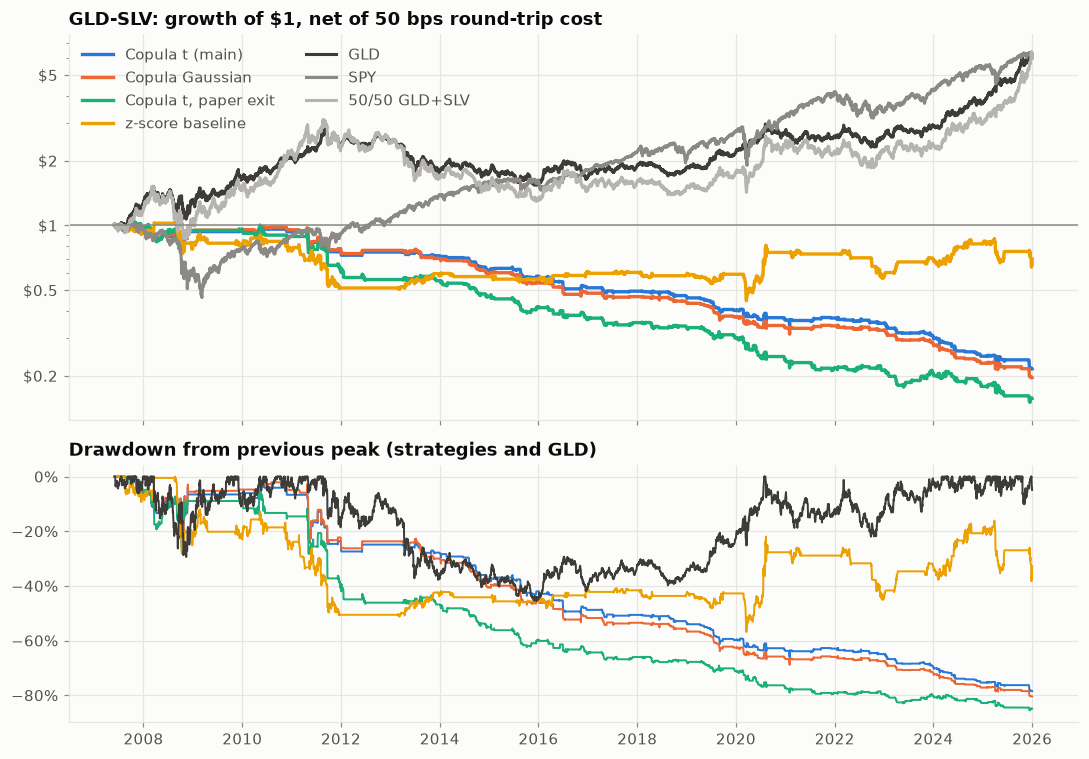

In [12]:
def load_returns(run_id):
    q = "SELECT date, ret FROM strategy_returns WHERE run_id = ? ORDER BY date"
    return pd.read_sql(q, conn, params=[run_id], parse_dates=["date"]).set_index("date")["ret"]

strategy_ids = {name: f"{MAIN}|{key}|50" for key, name in SPEC_NAMES.items()}
bench_ids = {b: f"{MAIN}|buy_hold|{b}" for b in ["GLD", "SPY", "50/50 GLD+SLV"]}
returns = {name: load_returns(rid) for name, rid in {**strategy_ids, **bench_ids}.items()}

fig = plots.equity_and_drawdown(returns, f"{MAIN}: growth of $1, net of 50 bps round-trip cost")
plots.save(fig, "05_equity_and_drawdown");

cost_bps,0.0000,10.0000,25.0000,50.0000,100.0000
spec,,,,,
Copula t (main),-0.0241,-0.0354,-0.0522,-0.0794,-0.1317
Copula Gaussian,-0.0236,-0.0360,-0.0543,-0.0841,-0.1410
"Copula t, paper exit",-0.0525,-0.0612,-0.0740,-0.0950,-0.1357
z-score baseline,0.0080,0.0025,-0.0058,-0.0194,-0.0460


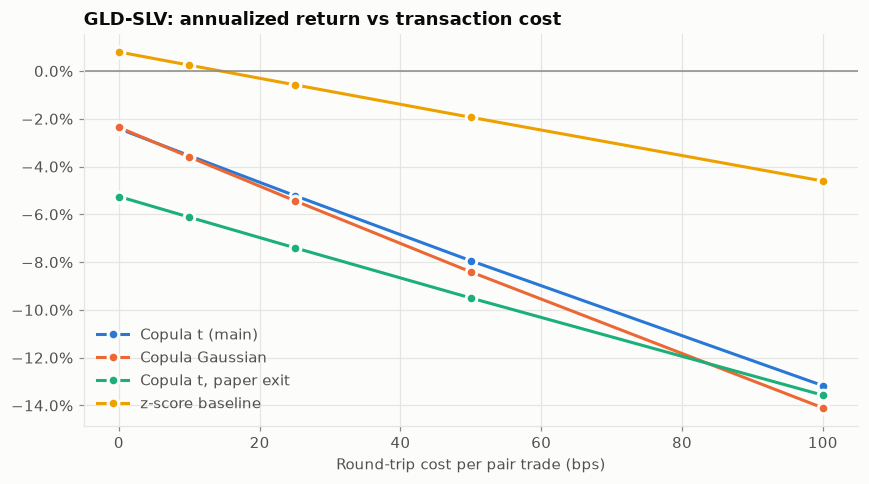

In [13]:
cost_table = (runs[(runs["pair"] == MAIN) & (runs["model"] != "buy_hold")]
              .pivot(index="spec", columns="cost_bps", values="ann_return")
              .loc[list(SPEC_NAMES.values())])
fig = plots.cost_sensitivity(cost_table, MAIN)
plots.save(fig, "06_cost_sensitivity")
cost_table

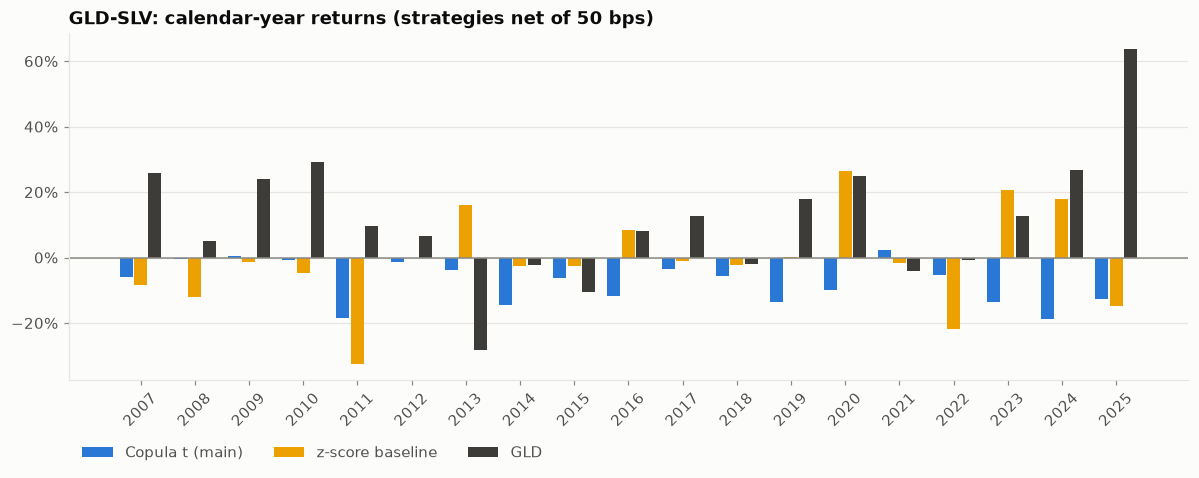

In [14]:
subset = {k: returns[k] for k in ["Copula t (main)", "z-score baseline", "GLD"]}
fig = plots.annual_returns(subset, f"{MAIN}: calendar-year returns (strategies net of 50 bps)")
plots.save(fig, "07_annual_returns");

exit_reason,reversion,take_profit,stop_loss,max_holding,end_of_data
Copula t (main),0.9491,0.0000,0.0463,0.0000,0.0046
Copula Gaussian,0.9536,0.0000,0.0422,0.0000,0.0042
"Copula t, paper exit",0.0000,0.4000,0.5353,0.0588,0.0059
z-score baseline,0.0980,0.0000,0.2745,0.6176,0.0098


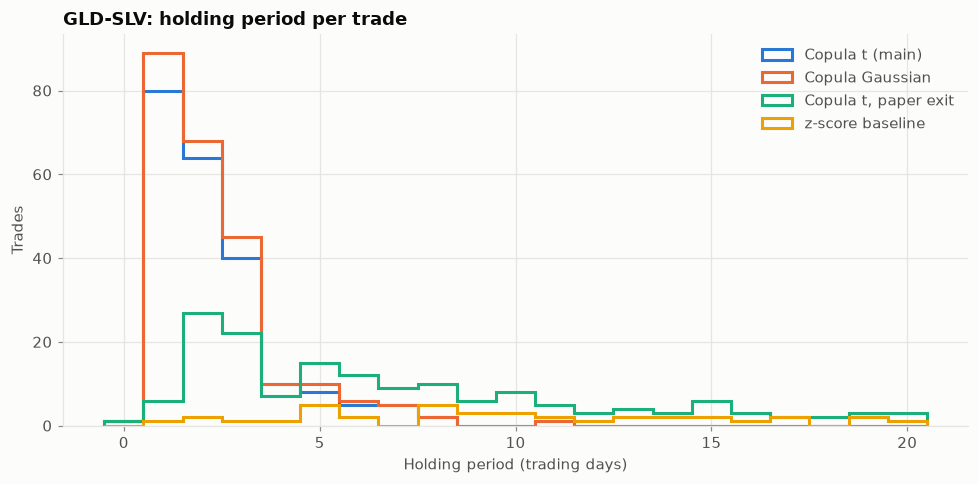

In [15]:
trades = {name: pd.read_sql("SELECT * FROM trades WHERE run_id = ?", conn, params=[rid])
          for name, rid in strategy_ids.items()}
fig = plots.holding_periods(trades, MAIN)
plots.save(fig, "08_holding_periods")
reasons = ["reversion", "take_profit", "stop_loss", "max_holding", "end_of_data"]
pd.DataFrame({n: t["exit_reason"].value_counts(normalize=True) for n, t in trades.items()}).reindex(reasons).fillna(0).T

## 5. Observations

Written from the tables above (run of 2026-10-24). These are descriptive results from one historical
path per pair; no significance tests have been run yet.

**RQ1, dependence beyond Pearson.** Pearson correlation and the Kendall-implied correlation differ by at
most 0.03 in every pair, so linear correlation does not badly misstate the overall strength of
co-movement. The tails are where the structure shows: both legs fall into their own 5% tail on 2.2–3.8%
of days (vs 0.25% under independence), and the lower-tail share exceeds the upper-tail share in three of
four pairs over the full sample (GDX-GDXJ is the exception) and in all four out of sample. Joint crashes are more common than joint rallies, which no symmetric copula (Gaussian or t) can
represent.

**RQ2, t vs Gaussian.** The t-copula has the lower AIC in 59–98% of months and the higher
out-of-sample log-likelihood in 56.5–69% of months, with a positive total out-of-sample log-likelihood
gain in all four pairs. Median ν is 4–10. Out of sample, the t-copula's predicted joint-tail frequency is
closer to the observed lower-tail frequency than the Gaussian's in every pair, but both still
under-predict lower-tail events and the t over-predicts upper-tail events in three of four pairs,
consistent with the asymmetry above. For GLD-SLV, ν sits near 100 (Gaussian-like) in several stretches
(e.g. 2016, 2023–2025), so the tail dependence is not stable over time.

**RQ3–RQ5, trading results.** None of the copula specifications earns a positive return on GLD-SLV, even
before costs (main spec: −2.4% a year gross, −7.9% net of 50 bps; Sharpe −0.37 / −0.99). Net of 50 bps,
all twelve copula runs across the four pairs have Sharpe ratios between −0.41 and −1.82. The z-score
baseline is roughly flat (net Sharpe −0.16 to +0.13) and buy-and-hold GLD returned about 10% a year over
the same period. The better-fitting t-copula does not produce better trades than the Gaussian copula
(net Sharpe −0.99 vs −1.03 on GLD-SLV).

**Why, as far as the data shows.** In the main spec 95% of trades close on the probability-reversion rule
after 2.3 days on average: the signal is computed from one day's return, so the next day's return
almost always moves the conditional probabilities back across 0.5. Gross win rate is 46%, and the
average trade loses 17 bps before costs. The paper's quantile exit lengthens holding periods to about
8 days, but more than half of those trades end at the stop-loss and the average gross trade loses 52 bps.

These results do not replicate the paper's positive returns. Candidate explanations, none tested here:
different assets and period (mostly after the paper's 1990–2014 sample), no copula-based pair selection
(the paper picks the top pairs out of 4,950 by in-sample profitability), and a 20-day holding cap
instead of the paper's 120-day path.

## 6. Limitations

- One price path per pair, four pairs chosen ex ante; no significance tests or bootstrap intervals yet.
- Returns are per $1 per leg, close-to-close, with no slippage model; short-selling of SLV/GDXJ/CVX/PEP is
  assumed available with no borrow fee.
- The paper's quantile rule occasionally produced a stop-loss at or above zero, or a take-profit at or
  below zero (25 of 635 trades across the four pairs); it was kept as specified rather than patched after
  seeing results.
- The t-copula ν estimate stops near 100 when the likelihood is flat; values there should be read as
  "no detectable tail dependence", not as an exact estimate.
- Free data: yfinance adjusted prices can be revised; the database stores the download timestamp.